# Assignment 1: PDF Text-to-Dashboard Pipeline (Nigeria, IMF 2025 Article IV)


**Part 1:** setup, PDF extraction, cleaning, token-aware chunking.  **Part 2:** summaries and the LLM-as-a-Judge loop.  **Part 3:** themes, JSON indicators, fallbacks, time series.  **Part 4:** RAG.  **Part 5:** dashboard.

## 0. Install and import libraries

Installs the libraries the pipeline needs: `pypdf` (PDF text), `tiktoken` (token counting), `google-genai` (Gemini API), `sentence-transformers` and `faiss-cpu` (local RAG), and `pandas` / `matplotlib` (tables and charts).

In [ ]:
!pip install -q pypdf tiktoken google-genai sentence-transformers faiss-cpu pandas matplotlib seaborn

Imports the standard libraries and creates the `outputs/` folder, where every machine-readable `.json` result is saved, as the brief requires.

In [ ]:
import re, json, os
from pathlib import Path
from collections import Counter

import pandas as pd
import tiktoken
from pypdf import PdfReader

# Folder where all machine-readable outputs (.json) will be saved
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

## 1. Gemini API setup
The key is read from Colab Secrets so it is never stored in the notebook.

Reads the Gemini API key from Colab Secrets (either `GOOGLE_API_KEY` or `GEMINI_API_KEY`), so the key is never stored in the notebook. It then creates the API client, sets `MODEL_NAME`, and runs a short connectivity test that should print `ready`.

In [ ]:
from google.colab import userdata
from google import genai
import time

def get_key():
    for name in ("GOOGLE_API_KEY", "GEMINI_API_KEY"):   # accepts either secret name
        try:
            return userdata.get(name)
        except Exception:
            continue
    raise RuntimeError("Add a Colab secret named GOOGLE_API_KEY (or GEMINI_API_KEY) and enable Notebook access.")

client = genai.Client(api_key=get_key())

# Change this one line to switch models (check Canvas for the model your module specifies).
MODEL_NAME = "gemini-3.8-flash"

# Quick connectivity test with retries (the API can be busy for a few minutes)
for attempt in range(6):
    try:
        resp = client.models.generate_content(model=MODEL_NAME, contents="Reply with the single word: ready")
        print(resp.text)
        break
    except Exception as e:
        print(f"Attempt {attempt + 1} failed: {str(e)[:100]}")
        time.sleep(15)

ready
ready


## 2. Document ingestion
Upload the PDF to the Colab session first, then set the path.

Finds the IMF Nigeria PDF (already in the session, by public download, or by upload) and extracts the raw text page by page with `pypdf`, keeping the page number of each page for traceability.

In [ ]:
PDF_CANDIDATES = ["002-article-A001-en.pdf", "1ngaea2025001-print-pdf.pdf"]   # either IMF file name works
IMF_URL = "https://meetings.imf.org/-/media/Files/Publications/CR/2025/English/1ngaea2025001-print-pdf.ashx"

def find_or_get_pdf():
    '''Use a PDF already in the session; else try the public IMF download; else ask for an upload.'''
    for name in PDF_CANDIDATES:
        if Path(name).exists():
            return name
    try:
        import requests
        r = requests.get(IMF_URL, timeout=60); r.raise_for_status()
        Path("imf_nigeria_2025_article_iv.pdf").write_bytes(r.content)
        return "imf_nigeria_2025_article_iv.pdf"
    except Exception as e:
        print("Automatic download failed:", e)
    from google.colab import files
    print("Please upload the IMF Nigeria 2025 Article IV Staff Report PDF now")
    return next(iter(files.upload()))

PDF_PATH = find_or_get_pdf()

reader = PdfReader(PDF_PATH)
print("Pages:", len(reader.pages))

# Raw text per page, keeping the PDF page index (1-based) for traceability
raw_pages = [{"page": i + 1, "text": p.extract_text() or ""} for i, p in enumerate(reader.pages)]
print(raw_pages[3]["text"][:600])

Pages: 85
3 
Table 1. Nigeria: Selected Economic and Financial Indicators, 2023–26 
  2023 2024 2025 2026 
5/8/2025 13:03 Act. Est. Proj. Proj. 
          
 National income and prices 
Annual percentage change  
(unless otherwise specified) 
Real GDP (at 2010 market prices) 2.9 3.4 3.4 3.2 
Oil GDP -2.2 5.5 4.9 2.3 
Non-oil GDP 3.2 3.3 3.3 3.3 
Non-oil non-agriculture GDP 3.9 4.1 3.7 3.7 
Production of crude oil (million barrels per day) 1.5 1.5 1.7 1.7 
Nominal GDP at market prices (trillions of naira) 234 277 320 367 
Nominal non-oil GDP (trillions of naira) 221 260 303 351 
Nominal GDP per capita (US


## 3. Extraction and cleaning
IMF pages carry running headers/footers ("INTERNATIONAL MONETARY FUND", page numbers, the copyright line) and
hard line breaks inside paragraphs. These are removed so they do not pollute chunks, summaries or retrieval.

Cleaning step: removes running headers and footers, page numbers and the copyright line, repairs hyphenated words and broken line breaks, and keeps table rows on their own lines so the numbers stay readable.

In [ ]:
HEADER_FOOTER_PATTERNS = [
    r"^\s*©\s*International Monetary Fund\. Not for Redistribution\s*$",
    r"^\s*\d{0,3}\s*INTERNATIONAL MONETARY FUND\s*\d{0,3}\s*$",
    r"^\s*NIGERIA\s*$",
    r"^\s*\d{1,3}\s*$",                      # lone page numbers
]
HF_REGEX = [re.compile(p, re.IGNORECASE) for p in HEADER_FOOTER_PATTERNS]

def clean_page(text: str) -> str:
    """Remove running headers/footers and repair line breaks within paragraphs."""
    kept = []
    for line in text.splitlines():
        if any(rx.match(line) for rx in HF_REGEX):
            continue
        kept.append(line.rstrip())
    text = "\n".join(kept)
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)          # re-join hyphenated words
    if not re.search(r"^Table [0-9]+[.]", text, re.M):      # keep table rows on their own lines
        text = re.sub(r"(?<![.:;!?\n])\n(?!\n|\d+\.\s|[•▪-])", " ", text)  # single newline -> space
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

clean_pages = [{"page": p["page"], "text": clean_page(p["text"])} for p in raw_pages]
print(clean_pages[3]["text"][:800])
print("\nCharacters before/after:",
      sum(len(p["text"]) for p in raw_pages), "->", sum(len(p["text"]) for p in clean_pages))

Table 1. Nigeria: Selected Economic and Financial Indicators, 2023–26
 2023 2024 2025 2026
5/8/2025 13:03 Act. Est. Proj. Proj.

 National income and prices
Annual percentage change
(unless otherwise specified)
Real GDP (at 2010 market prices) 2.9 3.4 3.4 3.2
Oil GDP -2.2 5.5 4.9 2.3
Non-oil GDP 3.2 3.3 3.3 3.3
Non-oil non-agriculture GDP 3.9 4.1 3.7 3.7
Production of crude oil (million barrels per day) 1.5 1.5 1.7 1.7
Nominal GDP at market prices (trillions of naira) 234 277 320 367
Nominal non-oil GDP (trillions of naira) 221 260 303 351
Nominal GDP per capita (US$) 1,597 806 836 887
GDP deflator 12.6 14.5 11.4 11.4
Consumer price index (annual average) 24.7 31.4 24.0 23.0
Consumer price index (end of period) 28.9 15.4 23.0 18.0
Investment and savings Percent of GDP
Gross national saving

Characters before/after: 203732 -> 196131


## 4. Section labelling
The staff report has a fixed structure: Context, Recent Economic Developments, Outlook and Risks,
Policy Discussions (lettered subsections A-E), Staff Appraisal, statistical Tables, then Annexes I-X.
Each page is tagged with the most recent heading so every chunk keeps its source section.
The same labels are later used as the "chapters" for the under-100-word summaries.

Tags every page with the report section it belongs to (Context, Recent Economic Developments, Outlook and Risks, Policy Discussions A-E, Staff Appraisal, Statistical Tables, Annexes). Later chunks, summaries and retrieved passages can then be traced back to their source section.

In [ ]:
MAIN_HEADINGS = {"CONTEXT": "Context",
                 "RECENT ECONOMIC DEVELOPMENTS": "Recent Economic Developments",
                 "OUTLOOK AND RISKS": "Outlook and Risks",
                 "STAFF APPRAISAL": "Staff Appraisal"}
POLICY_SUBSECTION = re.compile(r"^([A-E])\. ([A-Z][A-Za-z,\- ]{8,70})$")
ANNEX = re.compile(r"^(Annex [IVX]+)\. (.+)$")
STOP_WORDS = re.compile(r" (Overall|This|Figure|Table|Risk Assessment Matrix1|[A-Z]\.|1\.)\b.*$")
TABLE = re.compile(r"^Table \d+\.")

def tag_sections(pages):
    current = "Front matter"
    for p in pages:
        lines = [l.strip() for l in p["text"].splitlines() if l.strip()]
        for line in lines[:40]:                       # headings sit near the top of a block
            if line.upper() in MAIN_HEADINGS:
                current = MAIN_HEADINGS[line.upper()]
            elif current.startswith(("Outlook", "Policy")) and POLICY_SUBSECTION.match(line):
                current = "Policy Discussions: " + line
            elif TABLE.match(line) and not current.startswith(("Annex", "Statistical")):
                current = "Statistical Tables"
            elif ANNEX.match(line):
                m = ANNEX.match(line)
                title = " ".join(STOP_WORDS.sub("", m.group(2)).split()[:7])   # short title only
                current = f"{m.group(1)}. {title}"
        p["section"] = current
    return pages

clean_pages = tag_sections(clean_pages)
for p in clean_pages:
    print(p["page"], p["section"])

1 Front matter
2 Front matter
3 Front matter
4 Statistical Tables
5 Statistical Tables
6 Statistical Tables
7 Statistical Tables
8 Statistical Tables
9 Context
10 Context
11 Recent Economic Developments
12 Recent Economic Developments
13 Recent Economic Developments
14 Outlook and Risks
15 Outlook and Risks
16 Outlook and Risks
17 Outlook and Risks
18 Policy Discussions: A. Calibrating Fiscal Policy in Uncertain Times
19 Policy Discussions: A. Calibrating Fiscal Policy in Uncertain Times
20 Policy Discussions: A. Calibrating Fiscal Policy in Uncertain Times
21 Policy Discussions: B. Continued Focus on Disinflation
22 Policy Discussions: C. Enhancing Resilience to External Shocks
23 Policy Discussions: C. Enhancing Resilience to External Shocks
24 Policy Discussions: C. Enhancing Resilience to External Shocks
25 Policy Discussions: D. Safeguarding Financial Stability
26 Policy Discussions: E. Growth, Governance and Climate Resilience
27 Staff Appraisal
28 Staff Appraisal
29 Staff Apprai

## 5. Token-aware chunking
Target 400 tokens per chunk (inside the required 300-500 range) with a 50-token overlap.
Tokens are counted with `tiktoken` (`cl100k_base`), used as a model-agnostic approximation of Gemini tokens.

Token-aware chunking: splits each section into overlapping windows of 400 tokens with a 50-token overlap (inside the 300-500 range in the brief). Tokens are counted with `tiktoken`, and each chunk keeps its section label and start page.

In [ ]:
ENC = tiktoken.get_encoding("cl100k_base")
CHUNK_TOKENS, OVERLAP_TOKENS = 400, 50

def chunk_section(text, section, first_page):
    """Split one section's text into overlapping token windows."""
    ids = ENC.encode(text)
    step = CHUNK_TOKENS - OVERLAP_TOKENS
    out = []
    for start in range(0, len(ids), step):
        window = ids[start:start + CHUNK_TOKENS]
        if len(window) < 100 and out:      # avoid tiny trailing chunk: merge into previous
            out[-1]["text"] += " " + ENC.decode(window)
            out[-1]["n_tokens"] = len(ENC.encode(out[-1]["text"]))
            break
        out.append({"section": section, "start_page": first_page,
                    "text": ENC.decode(window), "n_tokens": len(window)})
    return out

def build_chunks(pages):
    # Group consecutive pages by section, remembering which page each part came from
    chunks, buf, sec, first = [], [], None, None
    for p in pages:
        if p["section"] != sec and buf:
            chunks += chunk_section("\n\n".join(buf), sec, first)
            buf, first = [], p["page"]
        if not buf: first = p["page"]
        sec = p["section"]
        buf.append(p["text"])
    if buf: chunks += chunk_section("\n\n".join(buf), sec, first)
    for i, c in enumerate(chunks): c["chunk_id"] = i
    return chunks

chunks = build_chunks(clean_pages)
df_chunks = pd.DataFrame(chunks)
print(len(chunks), "chunks")
print(df_chunks["n_tokens"].describe())
print(df_chunks.groupby("section")["chunk_id"].count())

142 chunks
count    142.000000
mean     383.978873
std       55.679741
min      101.000000
25%      400.000000
50%      400.000000
75%      400.000000
max      498.000000
Name: n_tokens, dtype: float64
section
Annex I. Country Engagement Strategy Summary A. Fragility in            5
Annex II. Status of 2024 Governance Recommendations                     1
Annex III. External Sector Assessment                                   9
Annex IV. Macroeconomic Impact of the Domestic Refinery                 4
Annex IX. Data Issues                                                   5
Annex V. Risk Assessment Matrix                                         3
Annex VI. Adverse Scenario                                              5
Annex VII. Capacity Development Strategy FY 2026 A. Context             6
Annex VIII. Sovereign Risk and Debt Sustainability Analysis            16
Annex X. Climate Trends                                                12
Context                                           

Saves the chunks to `outputs/chunks.json`.

In [ ]:
# Save chunks to disk (machine-readable output required by the brief)
with open(OUT_DIR / "chunks.json", "w") as f:
    json.dump(chunks, f, indent=2)
print("Saved", OUT_DIR / "chunks.json")

Saved outputs/chunks.json


# PART 2: Summaries and the LLM-as-a-Judge loop

**Design:** map-reduce summarisation.
1. *Map:* each report section is summarised on its own (under 100 words).
2. *Reduce:* the executive summary is written from the section summaries only.
3. *Judge:* a second LLM call scores every summary for **consistency, completeness and factual alignment** against the source text.
4. *Improve:* if a summary scores below 4 on any criterion, it is regenerated once using the judge's feedback (prompt v2), and judged again.

Each step logs the prompt version, so you can discuss prompt optimisation and failure modes in the report.

## 6. LLM helper with retries

LLM helper: `call_llm` is the single function through which Gemini calls are made. It spaces calls out, retries on errors, and can request schema-constrained JSON. `word_count` is used to check the under-100-words rule, and `JUDGE_MODEL_NAME` sets the model used as the judge.

In [ ]:
import time
from google.genai import types

# The judge can be the same model with a different system prompt, or a different model for more independence.
JUDGE_MODEL_NAME = MODEL_NAME

MIN_INTERVAL = 6.5     # seconds between calls: keeps the free tier (about 10 requests/min) happy. Use 0 on a paid key.
_last_call = [0.0]

def call_llm(prompt, model=None, system=None, temperature=0.0, json_mode=False, schema=None, retries=6):
    '''Single place where every LLM call goes: throttling, retries/backoff, and a JSON fallback if a schema is rejected.'''
    use_schema = schema
    for attempt in range(retries):
        gap = MIN_INTERVAL - (time.time() - _last_call[0])
        if gap > 0:
            time.sleep(gap)
        cfg = types.GenerateContentConfig(
            temperature=temperature,
            system_instruction=system,
            response_mime_type="application/json" if (json_mode or use_schema is not None) else None,
            response_schema=use_schema,
        )
        try:
            _last_call[0] = time.time()
            r = client.models.generate_content(model=model or MODEL_NAME, contents=prompt, config=cfg)
            return r.text
        except Exception as e:
            msg = str(e).lower()
            if use_schema is not None and ("schema" in msg or "default" in msg):
                # The SDK/model rejected the schema object: fall back to JSON mode with the schema written in the prompt
                prompt += "\n\nReturn ONLY valid JSON matching this JSON Schema:\n" + json.dumps(schema.model_json_schema())
                use_schema, json_mode = None, True
                print("Schema rejected by the API; falling back to JSON mode with the schema in the prompt")
                continue
            wait = min(10 * 2 ** attempt, 90)
            print(f"API error ({e.__class__.__name__}); retrying in {wait}s")
            time.sleep(wait)
    raise RuntimeError("LLM call failed after retries")

def word_count(s): return len(s.split())

## 7. Build the section texts
Every prose section is summarised: the main report sections (Context to Staff Appraisal) and Annexes I-X.
Statistical tables hold numbers, not prose, so they are used later for the indicator extraction instead.

Groups the cleaned page text by section into `section_texts`, one text per prose section. Statistical tables are left out because they hold numbers rather than prose. The printed token counts show the size of each section.

In [ ]:
section_texts = {}
for p in clean_pages:
    s = p["section"]
    if s.startswith(("Statistical", "Front")):
        continue
    section_texts.setdefault(s, []).append(p["text"])
section_texts = {k: "\n\n".join(v) for k, v in section_texts.items()}

for k, v in section_texts.items():
    print(f"{k[:60]:60s} {len(ENC.encode(v)):>6} tokens")

Context                                                         527 tokens
Recent Economic Developments                                   1298 tokens
Outlook and Risks                                              1323 tokens
Policy Discussions: A. Calibrating Fiscal Policy in Uncertai   1665 tokens
Policy Discussions: B. Continued Focus on Disinflation          587 tokens
Policy Discussions: C. Enhancing Resilience to External Shoc   1285 tokens
Policy Discussions: D. Safeguarding Financial Stability         562 tokens
Policy Discussions: E. Growth, Governance and Climate Resili    348 tokens
Staff Appraisal                                                1314 tokens
Annex I. Country Engagement Strategy Summary A. Fragility in   1653 tokens
Annex II. Status of 2024 Governance Recommendations             345 tokens
Annex III. External Sector Assessment                          2996 tokens
Annex IV. Macroeconomic Impact of the Domestic Refinery        1497 tokens
Annex V. Risk Assessment 

## 8. Prompts and the section summariser
The prompt has explicit constraints (length, no outside facts, keep numbers exact). A shortening loop enforces the
under-100-words rule if the model overshoots.

Completes the section summaries that were still missing. `summarise_quick` calls Gemini, tries several models in turn if one is busy or out of quota, and enforces the under-100-words rule with a shortening loop.

In [ ]:
import time, json
from google.genai import types

MODELS_TO_TRY = ["gemini-3.8-flash", "gemini-3.5-flash-lite", "gemini-3.5-flash"]
MIN_INTERVAL = 3.0
_last_call = [0.0]

def call_llm(prompt, model=None, system=None, temperature=0.0, json_mode=False, schema=None, retries=3):
    '''Every LLM call goes through here: throttling, real error messages, and automatic model switching.'''
    global MODEL_NAME, JUDGE_MODEL_NAME
    first = model or MODEL_NAME
    candidates = [first] + [m for m in MODELS_TO_TRY if m != first]
    use_schema = schema
    last_error = ""
    for cand in candidates:
        for attempt in range(retries):
            gap = MIN_INTERVAL - (time.time() - _last_call[0])
            if gap > 0:
                time.sleep(gap)
            cfg = types.GenerateContentConfig(
                temperature=temperature,
                system_instruction=system,
                response_mime_type="application/json" if (json_mode or use_schema is not None) else None,
                response_schema=use_schema,
            )
            try:
                _last_call[0] = time.time()
                r = client.models.generate_content(model=cand, contents=prompt, config=cfg)
                if cand != first:
                    print(f"Switched model: {first} -> {cand}")
                    if first == MODEL_NAME:
                        MODEL_NAME = cand
                    if first == JUDGE_MODEL_NAME:
                        JUDGE_MODEL_NAME = cand
                return r.text
            except Exception as e:
                last_error = str(e)
                msg = last_error.lower()
                print(f"[{cand}] {e.__class__.__name__}: {last_error[:160]}")
                if use_schema is not None and ("schema" in msg or "default" in msg):
                    prompt += "\n\nReturn ONLY valid JSON matching this JSON Schema:\n" + json.dumps(schema.model_json_schema())
                    use_schema, json_mode = None, True
                    continue
                if any(k in msg for k in ("429", "quota", "resource_exhausted", "404", "not_found", "not found")):
                    break
                time.sleep(10 * (attempt + 1))
    raise RuntimeError("All models failed. Last error: " + last_error[:300])

SUMMARY_SYSTEM = (
    "You are a careful financial-stability analyst summarising an IMF staff report. "
    "Use ONLY the text supplied. Never add facts, numbers or names that are not in the text. "
    "Keep figures exactly as written, with their units."
)

SUMMARY_PROMPT_V1 = '''Summarise the report section below in FEWER THAN 100 WORDS (aim for 70-90).
Rules:
- One plain paragraph. No bullets, no headings.
- Prioritise macroeconomic and financial-stability findings, key numbers and risks.
- Do not mention anything that is not in the text.

SECTION: {name}
TEXT:
{text}
'''

SHORTEN_PROMPT = '''The summary below has {n} words. Rewrite it in at most 90 words, keeping the most important
numbers and the main message. Output only the rewritten summary.

{summary}
'''

MAX_DIRECT_TOKENS = 8000        # one call per section; longer sections go through the chunk-by-chunk loop
MIN_TOKENS_TO_SUMMARISE = 150   # sections with only a heading plus figures (e.g. Annex X) are skipped

CHUNK_NOTE_PROMPT = '''Write a note of at most 60 words on the excerpt below. Keep key numbers exactly as written.
Use only the text. Output only the note.

EXCERPT:
{text}
'''

def condense_long_section(name, text):
    '''Summarisation loop: summarise each chunk of a long section, then summarise the notes together.'''
    parts = [c for c in chunks if c["section"] == name]
    notes = [call_llm(CHUNK_NOTE_PROMPT.format(text=c["text"]), system=SUMMARY_SYSTEM).strip() for c in parts]
    return "NOTES FROM EACH PART OF THE SECTION (in order):\n" + "\n".join(f"- {n}" for n in notes)

def summarise_section(name, text, prompt=SUMMARY_PROMPT_V1, extra=""):
    map_reduce = len(ENC.encode(text)) > MAX_DIRECT_TOKENS
    working_text = condense_long_section(name, text) if map_reduce else text
    summary = call_llm(prompt.format(name=name, text=working_text) + extra, system=SUMMARY_SYSTEM).strip()
    shortened = 0
    while word_count(summary) >= 100 and shortened < 3:
        summary = call_llm(SHORTEN_PROMPT.format(n=word_count(summary), summary=summary),
                           system=SUMMARY_SYSTEM).strip()
        shortened += 1
    return {"summary": summary, "words": word_count(summary), "shorten_rounds": shortened, "map_reduce": map_reduce}

skipped_sections = [k for k, v in section_texts.items() if len(ENC.encode(v)) < MIN_TOKENS_TO_SUMMARISE]
section_texts = {k: v for k, v in section_texts.items() if k not in skipped_sections}
print("Skipped (no prose to summarise):", skipped_sections)

# Keeps any summaries already finished; only the missing ones are done
if "summaries_v1" not in globals():
    summaries_v1 = {}
print("Already done:", len(summaries_v1), "of", len(section_texts))

for name, text in section_texts.items():
    if name in summaries_v1:
        continue
    t0 = time.time()
    try:
        summaries_v1[name] = summarise_section(name, text)
        print(f"[{summaries_v1[name]['words']} words, {time.time() - t0:.0f}s] {name}")
        print(summaries_v1[name]["summary"], "\n")
    except Exception as e:
        print("FAILED:", name, str(e)[:150])

print("Done:", len(summaries_v1), "of", len(section_texts))

Skipped (no prose to summarise): []
Already done: 0 of 19
[gemini-3.8-flash] ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on
Switched model: gemini-3.8-flash -> gemini-3.5-flash-lite
[90 words, 4s] Context
Nigeria’s sustained 2023 reforms have strengthened shock resilience, stabilizing the naira, boosting portfolio inflows, and securing a late 2024 external market entry alongside an April 2025 credit upgrade. Security improvements increased oil and agriculture output. However, reform benefits are uneven, with 2024 poverty at 46 percent and 31 million Nigerians food insecure amid a cost-of-living crisis and public discontent over tariff increases. Furthermore, heightened external uncertainty, including lower oil prices and tightening global financial conditions, weighs on external and fiscal positions, while official development assistance reached $1.5 billion in

## 9. Executive summary (reduce step)

Upgraded LLM helper: redefines `call_llm` with shorter spacing between calls and automatic switching between the models in `MODELS_TO_TRY` when one is busy or out of quota. It also prints the real error message. All later blocks use this version.

In [ ]:
import time, json
from google.genai import types

MODELS_TO_TRY = ["gemini-3.8-flash", "gemini-3.5-flash-lite", "gemini-3.5-flash"]
MIN_INTERVAL = 3.0
_last_call = [0.0]

def call_llm(prompt, model=None, system=None, temperature=0.0, json_mode=False, schema=None, retries=3):
    '''Every LLM call goes through here: throttling, real error messages, and automatic model switching.'''
    global MODEL_NAME, JUDGE_MODEL_NAME
    first = model or MODEL_NAME
    candidates = [first] + [m for m in MODELS_TO_TRY if m != first]
    use_schema = schema
    last_error = ""
    for cand in candidates:
        for attempt in range(retries):
            gap = MIN_INTERVAL - (time.time() - _last_call[0])
            if gap > 0:
                time.sleep(gap)
            cfg = types.GenerateContentConfig(
                temperature=temperature,
                system_instruction=system,
                response_mime_type="application/json" if (json_mode or use_schema is not None) else None,
                response_schema=use_schema,
            )
            try:
                _last_call[0] = time.time()
                r = client.models.generate_content(model=cand, contents=prompt, config=cfg)
                if cand != first:
                    print(f"Switched model: {first} -> {cand}")
                    if first == MODEL_NAME:
                        MODEL_NAME = cand
                    if first == JUDGE_MODEL_NAME:
                        JUDGE_MODEL_NAME = cand
                return r.text
            except Exception as e:
                last_error = str(e)
                msg = last_error.lower()
                print(f"[{cand}] {e.__class__.__name__}: {last_error[:160]}")
                if use_schema is not None and ("schema" in msg or "default" in msg):
                    prompt += "\n\nReturn ONLY valid JSON matching this JSON Schema:\n" + json.dumps(schema.model_json_schema())
                    use_schema, json_mode = None, True
                    continue
                if any(k in msg for k in ("429", "quota", "resource_exhausted", "404", "not_found", "not found")):
                    break                      # this model is out of quota or unavailable: try the next one
                time.sleep(10 * (attempt + 1))
    raise RuntimeError("All models failed. Last error: " + last_error[:300])

print("call_llm updated")

call_llm updated


## 10. The judge (second LLM call)
The judge sees the **source text** and the **summary**, and returns strict JSON scores from 1 (poor) to 5 (excellent):
- **consistency**: no contradictions with the source
- **completeness**: covers the main points of the source
- **factual_alignment**: every number and claim is supported by the source

It also lists any unsupported claims, which is what you check by hand against the PDF.

The judge (second LLM): defines a strict auditor prompt and a JSON parser, then scores each section summary from 1 to 5 for consistency, completeness and factual alignment against the source text. The results are collected in `df_judge`.

In [ ]:
JUDGE_SYSTEM = (
    "You are a strict auditor of AI-generated summaries of IMF reports. "
    "Judge only against the SOURCE text. Be critical; give 5 only if nothing is wrong. "
    "Respond with valid JSON only."
)

JUDGE_PROMPT = '''Evaluate the SUMMARY against the SOURCE.

Score each from 1 to 5:
- consistency: the summary does not contradict the source
- completeness: the summary covers the main points of the source
- factual_alignment: every number, name and claim in the summary is supported by the source

Return JSON exactly in this form:
{{"consistency": 0, "completeness": 0, "factual_alignment": 0,
  "unsupported_claims": ["..."], "comment": "one or two sentences"}}

SOURCE:
{source}

SUMMARY:
{summary}
'''

def parse_json(text):
    text = text.strip()
    if text.startswith("```"):
        text = text.strip("`")
        text = text[4:] if text.lower().startswith("json") else text
    return json.loads(text)

def judge(source, summary):
    raw = call_llm(JUDGE_PROMPT.format(source=source, summary=summary),
                   model=JUDGE_MODEL_NAME, system=JUDGE_SYSTEM, json_mode=True)
    try:
        return parse_json(raw)
    except Exception:
        return {"consistency": None, "completeness": None, "factual_alignment": None,
                "unsupported_claims": [], "comment": "JUDGE OUTPUT NOT VALID JSON: " + raw[:200]}

judge_rows = []
for name, item in summaries_v1.items():
    res = judge(section_texts[name], item["summary"])
    judge_rows.append({"item": name, "prompt_version": "v1", **res})
    time.sleep(1)

df_judge = pd.DataFrame(judge_rows)
df_judge[["item", "prompt_version", "consistency", "completeness", "factual_alignment"]]

,item,prompt_version,consistency,completeness,factual_alignment
0,Context,v1,5,5,5
1,Recent Economic Developments,v1,5,5,5
2,Outlook and Risks,v1,5,5,5
3,Policy Discussions: A. Calibrating Fiscal Poli...,v1,5,5,5
4,Policy Discussions: B. Continued Focus on Disi...,v1,5,5,5
5,Policy Discussions: C. Enhancing Resilience to...,v1,5,5,5
6,Policy Discussions: D. Safeguarding Financial ...,v1,5,5,5
7,"Policy Discussions: E. Growth, Governance and ...",v1,5,5,5
8,Staff Appraisal,v1,5,5,5
9,Annex I. Country Engagement Strategy Summary A...,v1,5,5,5


## 11. Improvement loop

Improvement loop: any summary scoring below 4 on a criterion is rewritten once with the judge's feedback (prompt v2) and judged again, so v1 and v2 scores can be compared in the report.

In [ ]:
def needs_fix(row):
    scores = [row.get(k) for k in ("consistency", "completeness", "factual_alignment")]
    return any(s is None or s < 4 for s in scores)

summaries_final = {k: dict(v, prompt_version="v1") for k, v in summaries_v1.items()}

for row in list(judge_rows):
    name = row["item"]
    if not needs_fix(row):
        continue
    feedback = (f"\n\nA reviewer found these problems with an earlier draft. Fix them.\n"
                f"Unsupported claims: {row.get('unsupported_claims')}\nComment: {row.get('comment')}\n"
                f"Include the most important facts and numbers; remove anything not in the text.")
    new = summarise_section(name, section_texts[name], extra=feedback)
    res = judge(section_texts[name], new["summary"])
    judge_rows.append({"item": name, "prompt_version": "v2", **res})
    summaries_final[name] = dict(new, prompt_version="v2")
    print("Regenerated:", name)
    time.sleep(1)

df_judge = pd.DataFrame(judge_rows)
df_judge[["item", "prompt_version", "consistency", "completeness", "factual_alignment"]]

,item,prompt_version,consistency,completeness,factual_alignment
0,Context,v1,5,5,5
1,Recent Economic Developments,v1,5,5,5
2,Outlook and Risks,v1,5,5,5
3,Policy Discussions: A. Calibrating Fiscal Poli...,v1,5,5,5
4,Policy Discussions: B. Continued Focus on Disi...,v1,5,5,5
5,Policy Discussions: C. Enhancing Resilience to...,v1,5,5,5
6,Policy Discussions: D. Safeguarding Financial ...,v1,5,5,5
7,"Policy Discussions: E. Growth, Governance and ...",v1,5,5,5
8,Staff Appraisal,v1,5,5,5
9,Annex I. Country Engagement Strategy Summary A...,v1,5,5,5


## 12. Judge the executive summary and save everything

Writes the executive summary from the final section summaries, judges it against the main report text, and saves `summaries.json` and `judge_scores_summaries.json`.

In [ ]:
SUMMARY_SYSTEM = ("You are a careful financial-stability analyst summarising an IMF staff report. "
    "Use ONLY the text supplied. Never add facts, numbers or names that are not in the text. "
    "Keep figures exactly as written, with their units.")

EXEC_PROMPT_V1 = """Using ONLY the section summaries below, write the executive summary of this IMF Article IV
report on Nigeria as 6-8 bullet points. Each bullet must be under 30 words.
Cover: growth, inflation, monetary policy, fiscal position, external position, financial sector,
main risks, and the main policy advice. Start every line with "- ".

SECTION SUMMARIES:
{summaries}
"""

def make_exec_summary(summaries_dict, prompt=EXEC_PROMPT_V1):
    joined = "\n\n".join(f"{k}: {v['summary']}" for k, v in summaries_dict.items())
    return call_llm(prompt.format(summaries=joined), system=SUMMARY_SYSTEM).strip()

SUMMARY_PROMPT_V1 = """Summarise the report section below in FEWER THAN 100 WORDS (aim for 70-90).
Rules:
- One plain paragraph. No bullets, no headings.
- Prioritise macroeconomic and financial-stability findings, key numbers and risks.
- Do not mention anything that is not in the text.

SECTION: {name}
TEXT:
{text}
"""

SHORTEN_PROMPT = """The summary below has {n} words. Rewrite it in at most 90 words, keeping the most important
numbers and the main message. Output only the rewritten summary.

{summary}
"""

def summarise_section(name, text, prompt=SUMMARY_PROMPT_V1, extra=""):
    summary = call_llm(prompt.format(name=name, text=text) + extra, system=SUMMARY_SYSTEM).strip()
    shortened = 0
    while word_count(summary) >= 100 and shortened < 3:
        summary = call_llm(SHORTEN_PROMPT.format(n=word_count(summary), summary=summary),
                           system=SUMMARY_SYSTEM).strip()
        shortened += 1
    return {"summary": summary, "words": word_count(summary), "shorten_rounds": shortened, "map_reduce": False}

print("Definitions added")

Definitions added


# PART 3: Task 2 - Thematic extraction, indicators and structured output

## 14. Thematic distribution scanning (7 themes)
Each theme has a keyword lexicon (regular expressions). Occurrences are counted in every chunk, then summed per theme and per
report section. Statistical tables are excluded because they contain numbers, not prose.
Note: lexicons overlap a little (e.g. "bank" can touch two themes). Say so in the report as a limitation.

Theme scan: counts keyword mentions for the 7 financial-stability themes in every chunk, totals them per theme and per section, and saves the result as `theme_counts.json`.

In [ ]:
THEME_KEYWORDS = {
    "Inflation & Prices": [r"inflation", r"disinflation", r"\bCPI\b", r"consumer price", r"price stability", r"food price"],
    "Interest Rates & Credit": [r"interest rate", r"policy rate", r"monetary policy", r"\btighten", r"\bcredit\b",
                                r"lending", r"cash reserve", r"\bOMOs?\b", r"yield"],
    "Housing & Real Estate": [r"housing", r"real estate", r"mortgage", r"propert(?:y|ies)", r"construction"],
    "Banking Capital & Liquidity": [r"capital adequacy", r"recapitali[sz]", r"\bTier 1\b", r"\bbanks?\b", r"banking",
                                    r"non-?performing", r"\bNPLs?\b", r"Basel", r"liquidity", r"buffers?"],
    "Sovereign Debt": [r"\bdebt\b", r"sovereign", r"eurobond", r"debt sustainability", r"interest payments",
                       r"borrowing", r"arrears", r"\bDSA\b"],
    "Labor Market Dynamics": [r"\blabou?r\b", r"employment", r"\bwages?\b", r"\bjobs?\b", r"workers", r"unemployment"],
    "Systemic Financial Risk": [r"financial stability", r"systemic", r"stress tests?", r"spillovers?", r"contagion",
                                r"vulnerabilit", r"fragil", r"financial sector"],
}
THEME_REGEX = {t: [re.compile(p, re.IGNORECASE) for p in pats] for t, pats in THEME_KEYWORDS.items()}

def count_themes(text):
    return {t: sum(len(rx.findall(text)) for rx in rxs) for t, rxs in THEME_REGEX.items()}

prose_chunks = [c for c in chunks if not c["section"].startswith(("Statistical", "Front"))]

rows = []
for c in prose_chunks:
    counts = count_themes(c["text"])
    c["theme_counts"] = counts
    c["dominant_theme"] = max(counts, key=counts.get) if sum(counts.values()) else "None"
    rows.append({"chunk_id": c["chunk_id"], "section": c["section"], **counts})

df_theme_chunks = pd.DataFrame(rows)
theme_totals = df_theme_chunks[list(THEME_KEYWORDS)].sum().sort_values(ascending=False)
theme_share = (theme_totals / theme_totals.sum() * 100).round(1)
df_theme_summary = pd.DataFrame({"mentions": theme_totals, "share_pct": theme_share})
print(df_theme_summary)

df_theme_by_section = df_theme_chunks.groupby("section")[list(THEME_KEYWORDS)].sum()

with open(OUT_DIR / "theme_counts.json", "w") as f:
    json.dump({"totals": theme_totals.to_dict(), "share_pct": theme_share.to_dict(),
               "by_section": df_theme_by_section.to_dict(orient="index"),
               "chunks_by_dominant_theme": Counter(c["dominant_theme"] for c in prose_chunks)}, f, indent=2)
print("Saved theme_counts.json")

                             mentions  share_pct
Banking Capital & Liquidity       180       27.5
Sovereign Debt                    177       27.0
Interest Rates & Credit           120       18.3
Inflation & Prices                100       15.3
Systemic Financial Risk            52        7.9
Labor Market Dynamics              22        3.4
Housing & Real Estate               4        0.6
Saved theme_counts.json


## 15. Qualitative risk insights (5-7 strengths, 5-7 vulnerabilities)
Schema-constrained output with pydantic: the model must return JSON in this exact shape. The counts (5-7) are enforced
in Python afterwards and the call is retried if the model breaks the limit.

Qualitative risk insights: asks Gemini, with a pydantic schema, for 5-7 growth strengths and 5-7 vulnerabilities. The counts are validated in Python (with retries), and the result is saved as `qualitative_insights.json`.

In [ ]:
from typing import List, Optional
from pydantic import BaseModel

class InsightItem(BaseModel):
    title: str
    explanation: str
    source_section: str

class RiskInsights(BaseModel):
    strengths: List[InsightItem]
    vulnerabilities: List[InsightItem]

body_text = "\n\n".join(f"[{name}]\n{txt}" for name, txt in section_texts.items())

INSIGHT_PROMPT = '''From the IMF staff report text below, extract:
- "strengths": between 5 and 7 national macroeconomic growth drivers / strengths
- "vulnerabilities": between 5 and 7 systemic vulnerabilities / challenges
Each item: a short title, an explanation of at most 30 words, and the report section it comes from.
Use ONLY facts in the text. Do not invent numbers.

TEXT:
{text}
'''

def get_insights(max_attempts=3):
    for attempt in range(max_attempts):
        raw = call_llm(INSIGHT_PROMPT.format(text=body_text), system=SUMMARY_SYSTEM, schema=RiskInsights)
        try:
            obj = RiskInsights.model_validate_json(raw)
        except Exception as e:
            print("Invalid JSON, retrying:", e); continue
        if 5 <= len(obj.strengths) <= 7 and 5 <= len(obj.vulnerabilities) <= 7:
            return obj
        print(f"Counts out of range ({len(obj.strengths)}/{len(obj.vulnerabilities)}), retrying")
    obj.strengths, obj.vulnerabilities = obj.strengths[:7], obj.vulnerabilities[:7]   # last resort: trim
    return obj

insights = get_insights()
for kind in ("strengths", "vulnerabilities"):
    print("\n" + kind.upper())
    for it in getattr(insights, kind):
        print(f"- {it.title}: {it.explanation} [{it.source_section}]")

with open(OUT_DIR / "qualitative_insights.json", "w") as f:
    json.dump(insights.model_dump(), f, indent=2)


STRENGTHS
- Foreign Exchange Market Liberalization: The authorities have implemented bold reforms including liberalizing and strengthening the functioning of the foreign exchange market, which brought stability to the naira and increased international reserves. [Context]
- Acceleration of Economic Growth: Growth accelerated in 2024, reaching 3.4 percent, driven mainly by hydrocarbon output and services, with hydrocarbon GDP growing by 5.5 percent as security improved. [Recent Economic Developments]
- Improvement in the External Position: The current account surplus increased to 9 percent of GDP in 2024, driven by hydrocarbon exports, compressed imports, lower oil sector repatriations, and stronger remittances. [Recent Economic Developments]
- Banking Sector Resilience: The banking sector remains resilient, liquid, and profitable, with banks' capital adequacy increasing to 15.3 percent at end-2024 and a liquidity ratio reaching 49 percent. [Recent Economic Developments]
- Fiscal Defici

## 16. Core indicator JSON extraction (target schema) with evidence
The 7 required fields are exactly the target schema. A separate `evidence` list records the quote and table each value
came from (or why it is missing), so you can audit it by hand.

**Conventions (write these in your report):** GDP growth = real GDP growth for the first projection year (2025);
inflation = CPI annual average for the latest estimate year (2024); NPL ratio and Tier 1 ratio = latest quarter (2024Q4);
policy rate = the *level* of the policy rate if stated; unemployment = rate if stated.

Core indicator extraction: defines the 7-field target schema (`CoreIndicators`) plus an evidence list, then asks Gemini to fill it from the report text under strict rules (no guessing, null when a value is not stated).

In [ ]:
import time as _time

class CoreIndicators(BaseModel):
    country_name: str
    gdp_growth_forecast_pct: Optional[float]
    headline_inflation_rate_pct: Optional[float]
    central_bank_policy_rate_pct: Optional[float]
    non_performing_loan_ratio: Optional[float]
    unemployment_rate_pct: Optional[float]
    tier_1_capital_ratio: Optional[float]

class Evidence(BaseModel):
    field: str
    source_quote: Optional[str]
    table_or_section: Optional[str]
    note_if_missing: Optional[str]

class ExtractionResult(BaseModel):
    indicators: CoreIndicators
    evidence: List[Evidence]

NUMERIC_FIELDS = [f for f in CoreIndicators.model_fields if f != "country_name"]

# Everything except annexes: main report + statistical tables (Table 1 and Table 8 hold most numbers)
extraction_source = "\n\n".join(f"[PDF page {p['page']} | {p['section']}]\n{p['text']}"
                                for p in clean_pages if not p["section"].startswith(("Annex", "Front")))

EXTRACT_SYSTEM = (
    "You extract numbers from IMF staff reports. Use ONLY the supplied text. "
    "If a value is not explicitly stated, return null and explain why in evidence.note_if_missing. "
    "NEVER guess, estimate or compute a value, and NEVER substitute a different indicator "
    "(for example do not use the total capital ratio where Tier 1 is requested). Percentages are plain numbers (31.4 not 0.314)."
)

EXTRACT_PROMPT = '''Extract the following indicators for the country in this report.
- country_name
- gdp_growth_forecast_pct: real GDP growth, FIRST PROJECTION year (2025), percent
- headline_inflation_rate_pct: CPI inflation, annual average, latest estimate year (2024), percent
- central_bank_policy_rate_pct: the LEVEL of the central bank policy rate (not a change in basis points), percent
- non_performing_loan_ratio: NPLs to total gross loans, latest quarter available (2024Q4), percent
- unemployment_rate_pct: unemployment rate, percent
- tier_1_capital_ratio: regulatory Tier 1 capital to risk-weighted assets, latest quarter (2024Q4), percent
Also return one evidence entry per numeric field: a short quote (under 25 words) copied from the text and the table
or section it came from, or a note explaining why the value is missing.

TEXT:
{text}
'''

GENERIC_PROMPT = '''Read the text and give me nigeria's country name, GDP growth forecast, headline inflation, central bank
policy rate, NPL ratio, unemployment rate and Tier 1 capital ratio as JSON with keys country_name,
gdp_growth_forecast_pct, headline_inflation_rate_pct, central_bank_policy_rate_pct, non_performing_loan_ratio,
unemployment_rate_pct, tier_1_capital_ratio.

TEXT:
{text}
'''

def run_extraction(use_system_and_schema=True, model=None):
    t0 = _time.time()
    try:
        if use_system_and_schema:
            raw = call_llm(EXTRACT_PROMPT.format(text=extraction_source), model=model,
                           system=EXTRACT_SYSTEM, schema=ExtractionResult)
            result = ExtractionResult.model_validate_json(raw)
            valid = True
        else:
            raw = call_llm(GENERIC_PROMPT.format(text=extraction_source), model=model)
            ind = CoreIndicators.model_validate(parse_json(raw))       # does it match the schema at all?
            result, valid = ExtractionResult(indicators=ind, evidence=[]), True
    except Exception as e:
        print("Extraction failed schema validation:", str(e)[:150])
        return {"result": None, "valid": False, "latency_s": round(_time.time() - t0, 1), "raw": None}
    return {"result": result, "valid": valid, "latency_s": round(_time.time() - t0, 1), "raw": raw}

main_run = run_extraction(True)
if main_run["result"] is None:
    raise RuntimeError("The main extraction failed. Re-run this cell; if it keeps failing, check MODEL_NAME and your API quota.")
extraction = main_run["result"]
print(json.dumps(extraction.indicators.model_dump(), indent=2))
print("latency:", main_run["latency_s"], "s")

{
  "country_name": "Nigeria",
  "gdp_growth_forecast_pct": 3.4,
  "headline_inflation_rate_pct": 31.4,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 4.9,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": 12.9
}
latency: 13.5 s


## 17. Fallback capture and automatic source check
- Any indicator the model returns as `null` is recorded in a **fallback log** with a reason.
- Every extracted number is also checked by plain string search in the source text (a cheap anti-hallucination test).
  This proves a number *appears* in the report; it does not prove it is the *right* number, so you still check by hand.

Fallback capture: any indicator returned as null is logged with a reason and a domain note (for example, unemployment is not reported and the policy rate level is not stated). Each extracted number is also string-searched in the source text as an anti-hallucination check.

In [ ]:
FALLBACK_VALUE = None     # the brief allows -1.0 or null; null keeps plots and statistics clean

DOMAIN_NOTES = {
    "unemployment_rate_pct": "The staff report does not tabulate an unemployment rate; its macro tables cover output, prices, fiscal, money and external data.",
    "central_bank_policy_rate_pct": "The text reports a change (+875 bps in 2024), not a level; check whether the level is only shown graphically (Figure 11).",
    "tier_1_capital_ratio": "Reported as 'Regulatory Tier 1 Capital to Risk-Weighted Assets' in Table 8; if missing, the model may have confused it with total capital.",
    "non_performing_loan_ratio": "Reported as 'Non-Performing Loans to Total Gross Loans' in Table 8.",
}

def appears_in_source(value, source):
    if value is None:
        return None
    forms = {f"{value:.1f}", f"{value:g}", f"{value:.2f}"}
    return any(re.search(rf"(?<![\d.]){re.escape(s)}(?![\d])", source) for s in forms)

def build_fallbacks(result):
    ind = result.indicators.model_dump()
    ev = {e.field: e for e in result.evidence}
    log, source_check = [], {}
    for field in NUMERIC_FIELDS:
        val = ind[field]
        source_check[field] = appears_in_source(val, extraction_source)
        if val is None:
            ind[field] = FALLBACK_VALUE
            log.append({"field": field, "fallback_value": FALLBACK_VALUE,
                        "model_reason": (ev[field].note_if_missing if field in ev else None),
                        "domain_note": DOMAIN_NOTES.get(field, "")})
    return ind, log, source_check

indicators_final, fallback_log, source_check = build_fallbacks(extraction)
print("Indicators:", json.dumps(indicators_final, indent=2))
print("\nFound in source text?", source_check)
print("\nFallback log:")
for row in fallback_log: print(row)

Indicators: {
  "country_name": "Nigeria",
  "gdp_growth_forecast_pct": 3.4,
  "headline_inflation_rate_pct": 31.4,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 4.9,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": 12.9
}

Found in source text? {'gdp_growth_forecast_pct': True, 'headline_inflation_rate_pct': True, 'central_bank_policy_rate_pct': None, 'non_performing_loan_ratio': True, 'unemployment_rate_pct': None, 'tier_1_capital_ratio': True}

Fallback log:
{'field': 'central_bank_policy_rate_pct', 'fallback_value': None, 'model_reason': 'The central bank policy rate is not explicitly stated in the provided text.', 'domain_note': 'The text reports a change (+875 bps in 2024), not a level; check whether the level is only shown graphically (Figure 11).'}
{'field': 'unemployment_rate_pct', 'fallback_value': None, 'model_reason': 'The unemployment rate is not explicitly stated in the provided text.', 'domain_note': 'The staff report does not tabulate 

## 18. Temporal trend identification (time series) and tidy transformation
The model extracts selected multi-year series from Table 1 and Table 8 into a *wide* matrix (one row per indicator,
one column per period). `pd.melt` then turns it into a *long* tidy DataFrame for plotting.
Every extracted value is string-checked against the table text.

Temporal trends: extracts multi-year series from Table 1 and Table 8 into a wide table, reshapes it with `pd.melt` into a long tidy DataFrame, and checks each value against the table text.

In [ ]:
class SeriesPoint(BaseModel):
    period: str
    value: Optional[float]

class Series(BaseModel):
    name: str
    unit: str
    source_table: str
    points: List[SeriesPoint]

class TimeSeriesResult(BaseModel):
    series: List[Series]

table_text = "\n\n".join(p["text"] for p in clean_pages
                         if re.search(r"Table 1\. Nigeria: Selected|Table 8\. Nigeria: Financial", p["text"]))

TS_PROMPT = '''From the two tables below, extract these series. Use the column headers as periods
(Table 1: 2021 ... 2030; Table 8: 2021, 2022, 2023, 2024Q1 ... 2024Q4). Use null for a cell that is blank or "...".
Series (name exactly as given):
1. "Real GDP growth" (percent, Table 1)
2. "CPI inflation, annual average" (percent, Table 1)
3. "CPI inflation, end of period" (percent, Table 1)
4. "Credit to the private sector (y/y)" (percent, Table 1)
5. "Broad money growth (end of period)" (percent, Table 1)
6. "Overall fiscal balance" (percent of GDP, Table 1)
7. "Public gross debt" (percent of GDP, Table 1)
8. "Non-performing loans to gross loans" (percent, Table 8)
9. "Regulatory Tier 1 capital to RWA" (percent, Table 8)
10. "Regulatory capital to RWA" (percent, Table 8)
Copy numbers exactly as printed.

TABLES:
{text}
'''

raw_ts = call_llm(TS_PROMPT.format(text=table_text), system=EXTRACT_SYSTEM, schema=TimeSeriesResult)
ts = TimeSeriesResult.model_validate_json(raw_ts)

wide_rows = []
for s in ts.series:
    row = {"indicator": s.name, "unit": s.unit, "source_table": s.source_table}
    row.update({pt.period: pt.value for pt in s.points})
    wide_rows.append(row)
df_wide = pd.DataFrame(wide_rows)

# ---- Optional human supplement: fill ONLY from the report itself (e.g. read the policy rate from Figure 11) ----
HUMAN_SUPPLEMENT = {
    # "Policy rate (MPR), end of period": {"unit": "percent", "source": "Figure 11 (read by hand)",
    #                                       "values": {"2021": 11.5, "2022": 16.5, "2023": 18.75, "2024": 27.5}},
}
for name, spec in HUMAN_SUPPLEMENT.items():
    df_wide = pd.concat([df_wide, pd.DataFrame([{"indicator": name, "unit": spec["unit"],
                                                  "source_table": spec["source"], **spec["values"]}])],
                        ignore_index=True)

id_cols = ["indicator", "unit", "source_table"]
df_long = df_wide.melt(id_vars=id_cols, var_name="period", value_name="value")      # <-- pd.melt (tidy format)
df_long = df_long.dropna(subset=["value"]).reset_index(drop=True)
df_long["verified_in_source"] = [appears_in_source(v, table_text) if "Figure" not in t else None
                                 for v, t in zip(df_long["value"], df_long["source_table"])]

print(df_wide.iloc[:, :8])
print("\nLong format:", df_long.shape, "| values not found in table text:",
      int((df_long["verified_in_source"] == False).sum()))
df_long.head(12)

                             indicator            unit source_table  2021  \
0                      Real GDP growth         percent      Table 1   3.6   
1        CPI inflation, annual average         percent      Table 1  17.0   
2         CPI inflation, end of period         percent      Table 1  15.6   
3   Credit to the private sector (y/y)         percent      Table 1  25.9   
4   Broad money growth (end of period)         percent      Table 1  14.2   
5               Overall fiscal balance  percent of GDP      Table 1  -5.5   
6                    Public gross debt  percent of GDP      Table 1  36.8   
7  Non-performing loans to gross loans         percent      Table 8   4.9   
8     Regulatory Tier 1 capital to RWA         percent      Table 8  12.5   
9            Regulatory capital to RWA         percent      Table 8  14.6   

   2022  2023  2024  2025  
0   3.3   2.9   3.4   3.4  
1  18.8  24.7  31.4  24.0  
2  21.3  28.9  15.4  23.0  
3  11.0  53.6  30.1  17.9  
4  17.4  51.

,indicator,unit,source_table,period,value,verified_in_source
0,Real GDP growth,percent,Table 1,2021,3.6,True
1,"CPI inflation, annual average",percent,Table 1,2021,17.0,True
2,"CPI inflation, end of period",percent,Table 1,2021,15.6,True
3,Credit to the private sector (y/y),percent,Table 1,2021,25.9,True
4,Broad money growth (end of period),percent,Table 1,2021,14.2,True
5,Overall fiscal balance,percent of GDP,Table 1,2021,-5.5,True
6,Public gross debt,percent of GDP,Table 1,2021,36.8,True
7,Non-performing loans to gross loans,percent,Table 8,2021,4.9,True
8,Regulatory Tier 1 capital to RWA,percent,Table 8,2021,12.5,True
9,Regulatory capital to RWA,percent,Table 8,2021,14.6,True


## 19. Evaluator validation (LLM audit of the JSON) and saving all outputs
The judge LLM checks each extracted indicator against the source text. Verdicts: `correct`, `incorrect`,
`unsupported`, or `correctly_null` (null is right because the report does not state it).

**What this code does:** Evaluator validation: a judge LLM audits each extracted indicator against the source (correct, incorrect, unsupported or correctly_null). All results are then saved as `.json` files: indicators, evidence, fallback log, audit and time series.

In [ ]:
JUDGE_EXTRACT_PROMPT = '''Audit these extracted indicators against the SOURCE text.
Conventions used: GDP growth = real GDP growth for 2025; inflation = CPI annual average for 2024;
NPL and Tier 1 ratios = 2024Q4; policy rate = the level of the policy rate; unemployment = unemployment rate.
For each of the 6 numeric fields give a verdict: "correct", "incorrect", "unsupported" (number not in source),
or "correctly_null" (null and the source really does not state it). If incorrect, give the right value.
Return JSON: {{"fields": [{{"field": "...", "verdict": "...", "comment": "..."}}]}}

EXTRACTED:
{extracted}

SOURCE:
{source}
'''

def audit_indicators(ind_dict, model=None):
    raw = call_llm(JUDGE_EXTRACT_PROMPT.format(extracted=json.dumps(ind_dict, indent=2), source=extraction_source),
                   model=model or JUDGE_MODEL_NAME, system=JUDGE_SYSTEM, json_mode=True)
    verdicts = parse_json(raw)["fields"]
    ok = sum(v["verdict"] in ("correct", "correctly_null") for v in verdicts)
    return verdicts, ok / max(len(verdicts), 1)

audit_verdicts, audit_accuracy = audit_indicators(extraction.indicators.model_dump())
print(pd.DataFrame(audit_verdicts))
print("Judge accuracy:", round(audit_accuracy, 2))

# Save every machine-readable output
with open(OUT_DIR / "indicators.json", "w") as f:
    json.dump(indicators_final, f, indent=2)
with open(OUT_DIR / "indicator_evidence.json", "w") as f:
    json.dump([e.model_dump() for e in extraction.evidence], f, indent=2)
with open(OUT_DIR / "fallback_log.json", "w") as f:
    json.dump(fallback_log, f, indent=2)
with open(OUT_DIR / "indicator_audit.json", "w") as f:
    json.dump({"verdicts": audit_verdicts, "accuracy": audit_accuracy, "source_string_check": source_check}, f, indent=2)
df_long.to_json(OUT_DIR / "timeseries_long.json", orient="records", indent=2)
print("Saved indicators, evidence, fallback log, audit and time series JSON files")

                          field         verdict  \
0       gdp_growth_forecast_pct         correct   
1   headline_inflation_rate_pct         correct   
2  central_bank_policy_rate_pct     unsupported   
3     non_performing_loan_ratio         correct   
4         unemployment_rate_pct  correctly_null   
5          tier_1_capital_ratio         correct   

                                             comment  
0  Real GDP growth for 2025 is stated as 3.4% in ...  
1  Consumer price index (annual average) for 2024...  
2  The policy rate value is not stated in the sou...  
3  Non-Performing Loans to Total Gross Loans for ...  
4  The unemployment rate is not stated in the sou...  
5  Regulatory Tier 1 Capital to Risk-Weighted Ass...  
Judge accuracy: 0.83
Saved indicators, evidence, fallback log, audit and time series JSON files


## 20. Model / system-directive comparison



Model and prompt comparison (the optional extension): runs the extraction with a generic prompt and with a `system_instruction` plus schema, and compares schema compliance, latency, judge accuracy and accuracy against `GROUND_TRUTH`, the hand-checked answer key.

In [ ]:
GROUND_TRUTH = {                     # None = the report does not state it
    "gdp_growth_forecast_pct": 3.4,           # Table 1, real GDP 2025 projection
    "headline_inflation_rate_pct": 31.4,      # Table 1, CPI annual average 2024
    "central_bank_policy_rate_pct": None,     # only a change (+875 bps) is stated
    "non_performing_loan_ratio": 4.9,         # Table 8, 2024Q4
    "unemployment_rate_pct": None,            # not reported
    "tier_1_capital_ratio": 12.9,             # Table 8, 2024Q4
}

def accuracy_vs_truth(ind_dict, truth=GROUND_TRUTH, tol=0.05):
    hits = 0
    for k, t in truth.items():
        v = ind_dict.get(k)
        hits += (v is None and t is None) or (v is not None and t is not None and abs(v - t) <= tol)
    return hits / len(truth)

BENCH_CONFIGS = [
    {"label": "A: generic prompt", "model": MODEL_NAME, "use_system_and_schema": False},
    {"label": "B: system_instruction + schema", "model": MODEL_NAME, "use_system_and_schema": True},
    # {"label": "B on flash-lite", "model": "gemini-2.5-flash-lite", "use_system_and_schema": True},
]

bench_rows = []
for cfg in BENCH_CONFIGS:
    run = run_extraction(cfg["use_system_and_schema"], model=cfg["model"])
    row = {"config": cfg["label"], "schema_valid": int(run["valid"]), "latency_s": run["latency_s"],
           "judge_accuracy": None, "truth_accuracy": None}
    if run["valid"]:
        ind = run["result"].indicators.model_dump()
        _, row["judge_accuracy"] = audit_indicators(ind)
        row["truth_accuracy"] = accuracy_vs_truth(ind)
    bench_rows.append(row)
    _time.sleep(1)

df_bench = pd.DataFrame(bench_rows)
df_bench.to_json(OUT_DIR / "model_comparison.json", orient="records", indent=2)
df_bench

[gemini-3.5-flash-lite] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again 
[gemini-3.5-flash-lite] ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again 


,config,schema_valid,latency_s,judge_accuracy,truth_accuracy
0,A: generic prompt,1,8.8,1.0,0.833333
1,B: system_instruction + schema,1,11.6,1.0,1.000000


# PART 4: Task 3 - RAG grounding and retrieval

## 21. Vector index (local embeddings + FAISS IndexFlatL2)
Embeddings come from a local DistilBERT-based sentence-transformers model (no API key needed).
Embeddings are L2-normalised, so the L2 distance in `IndexFlatL2` ranks passages the same way cosine similarity would.

Builds the local RAG index: embeds every chunk with a DistilBERT-based sentence-transformers model, normalises the vectors and stores them in a FAISS `IndexFlatL2`. The `retrieve` function returns the top-k passages for a query.

In [ ]:
import numpy as np, faiss
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "sentence-transformers/multi-qa-distilbert-cos-v1"     # DistilBERT-based retrieval model
embedder = SentenceTransformer(EMBED_MODEL)
embedder.max_seq_length = 512

index_chunks = [c for c in chunks if not c["section"].startswith("Front")]
emb = embedder.encode([c["text"] for c in index_chunks], batch_size=32, show_progress_bar=True,
                      normalize_embeddings=True).astype("float32")

faiss_index = faiss.IndexFlatL2(emb.shape[1])
faiss_index.add(emb)
print("Indexed", faiss_index.ntotal, "chunks, dimension", emb.shape[1])

def retrieve(query, k=4):
    q = embedder.encode([query], normalize_embeddings=True).astype("float32")
    dist, idx = faiss_index.search(q, k)
    return [{"chunk_id": index_chunks[i]["chunk_id"], "section": index_chunks[i]["section"],
             "start_page": index_chunks[i]["start_page"], "distance": float(d), "text": index_chunks[i]["text"]}
            for d, i in zip(dist[0], idx[0])]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/9.52k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/523 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  265MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Indexed 137 chunks, dimension 768


## 22. Grounded answers vs ungrounded answers (hallucination test)
For each factual query the notebook gets (a) an answer **grounded** in the retrieved passages and (b) an **ungrounded**
answer from the model alone. The judge scores both for faithfulness to the retrieved passages. A question the report does
not answer (like an exact inflation-target date) should get "not stated in the report" when grounded.

Runs the factual queries. For each one, a grounded answer (using only the retrieved passages) and an ungrounded answer (model alone) are generated, then scored by the judge for faithfulness and relevance. Results are saved to `rag_results.json`.

In [ ]:
RAG_QUERIES = [
    "What bank recapitalization requirement and deadline does the report mention?",
    "What stress testing does the central bank conduct and what do staff recommend?",
    "What does the report say about the timeline for moving to inflation targeting?",
    "What capital buffer or capital adequacy measures are recommended for Nigerian banks?",
]

GROUNDED_PROMPT = '''Answer the question using ONLY the passages below. Cite the passage numbers like [2].
If the passages do not contain the answer, reply exactly: "Not stated in the retrieved passages."

QUESTION: {q}

PASSAGES:
{ctx}
'''

RAG_JUDGE_PROMPT = '''Score the ANSWER for the QUESTION using only the PASSAGES.
faithfulness (1-5): every claim in the answer is supported by the passages (a correct "not stated" answer scores 5).
relevance (1-5): the answer addresses the question.
Return JSON: {{"faithfulness": 0, "relevance": 0, "comment": "..."}}

QUESTION: {q}
PASSAGES:
{ctx}
ANSWER:
{a}
'''

rag_results = []
for q in RAG_QUERIES:
    hits = retrieve(q, k=4)
    ctx = "\n\n".join(f"[{i+1}] (section: {h['section']}, page {h['start_page']}) {h['text']}" for i, h in enumerate(hits))
    grounded = call_llm(GROUNDED_PROMPT.format(q=q, ctx=ctx), system=SUMMARY_SYSTEM).strip()
    ungrounded = call_llm(f"Answer in 2-3 sentences about the IMF 2025 Article IV report on Nigeria: {q}").strip()
    jg = parse_json(call_llm(RAG_JUDGE_PROMPT.format(q=q, ctx=ctx, a=grounded), model=JUDGE_MODEL_NAME,
                             system=JUDGE_SYSTEM, json_mode=True))
    ju = parse_json(call_llm(RAG_JUDGE_PROMPT.format(q=q, ctx=ctx, a=ungrounded), model=JUDGE_MODEL_NAME,
                             system=JUDGE_SYSTEM, json_mode=True))
    rag_results.append({"query": q, "retrieved": [{k: h[k] for k in ("chunk_id", "section", "start_page", "distance")} for h in hits],
                        "grounded_answer": grounded, "ungrounded_answer": ungrounded,
                        "judge_grounded": jg, "judge_ungrounded": ju})
    print("Q:", q); print("  GROUNDED:", grounded[:300]); print("  UNGROUNDED:", ungrounded[:300])
    print("  faithfulness grounded/ungrounded:", jg.get("faithfulness"), "/", ju.get("faithfulness"), "\n")
    _time.sleep(1)

df_rag = pd.DataFrame([{"query": r["query"][:60],
                        "faith_grounded": r["judge_grounded"].get("faithfulness"),
                        "faith_ungrounded": r["judge_ungrounded"].get("faithfulness"),
                        "relevance_grounded": r["judge_grounded"].get("relevance")} for r in rag_results])
with open(OUT_DIR / "rag_results.json", "w") as f:
    json.dump(rag_results, f, indent=2)
df_rag

Q: What bank recapitalization requirement and deadline does the report mention?
  GROUNDED: Based on the provided passages, banks have raised half of the required capital to meet new minimum capital thresholds that will become effective in March 2026 [1].
  UNGROUNDED: The IMF's 2025 Article IV report on Nigeria notes the Central Bank of Nigeria's (CBN) directive to significantly increase the minimum paid-in capital for commercial banks to enhance financial stability and resilience. Specifically, the banks are required to meet these new capitalization thresholds b
  faithfulness grounded/ungrounded: 5 / 4 

Q: What stress testing does the central bank conduct and what do staff recommend?
  GROUNDED: Based on the provided passages, the CBN (central bank) conducts monthly stress tests [1]. 

Regarding what staff recommend, the staff make several recommendations regarding safeguarding financial stability and related banking and credit issues:
* Staff encourage the CBN to further improve t

,query,faith_grounded,faith_ungrounded,relevance_grounded
0,What bank recapitalization requirement and dea...,5,4,5
1,What stress testing does the central bank cond...,5,2,5
2,What does the report say about the timeline fo...,5,2,5
3,What capital buffer or capital adequacy measur...,3,2,5


# PART 5: Task 4 - Visualisation dashboard
Four distinct plots, saved at dpi 300 with titles, legends, grid lines and readable fonts:
1. Horizontal bar: thematic density across the 7 themes
2. Line plot: inflation (and the policy rate if you supplied it) over time
3. Bar chart: model/prompt-configuration comparison (judge score and accuracy against the answer key)
4. Scatter: private credit growth vs NPL ratio by year

Dashboard: defines four plots (theme density, inflation path, prompt-configuration comparison, and credit growth vs NPL ratio), saves each at 300 dpi, and combines them into one 2x2 `dashboard.png`.

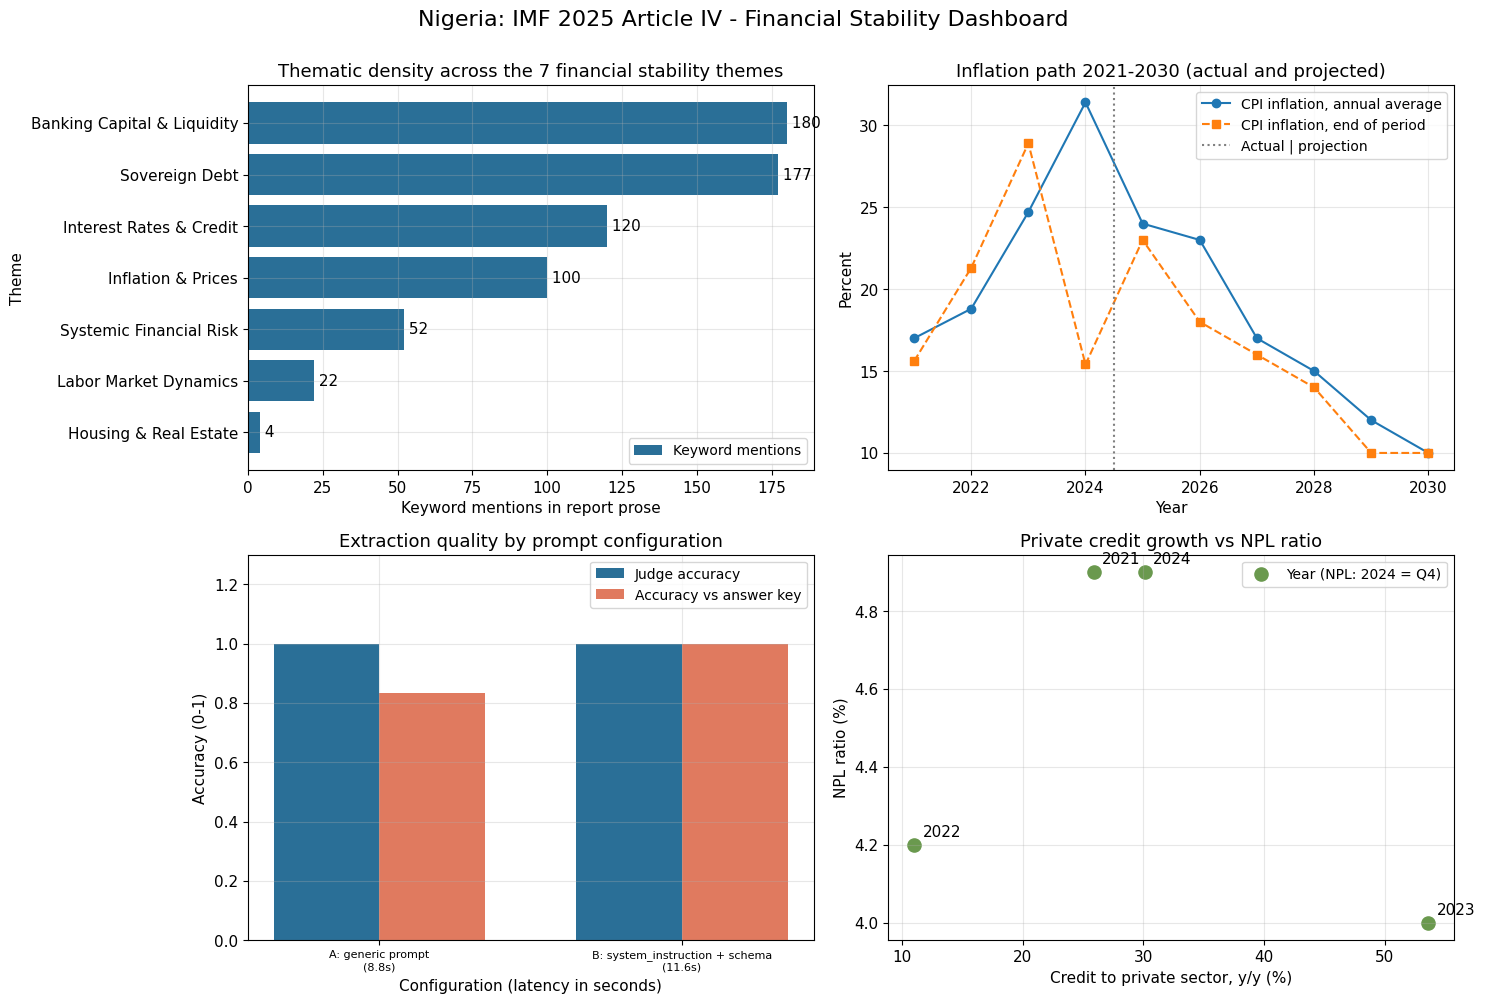

['1_theme_density.png', '2_inflation_path.png', '3_model_comparison.png', '4_credit_vs_npl.png', 'dashboard.png']


In [ ]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11, "legend.fontsize": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

def series_by_year(name_contains):
    sub = df_long[df_long["indicator"].str.contains(name_contains, case=False, regex=False)]
    sub = sub[sub["period"].str.fullmatch(r"\d{4}")]
    return sub.assign(year=sub["period"].astype(int)).sort_values("year")

def plot_themes(ax):
    data = df_theme_summary["mentions"].sort_values()
    ax.barh(data.index, data.values, color="#2a6f97", label="Keyword mentions")
    for y, v in enumerate(data.values): ax.text(v, y, f" {int(v)}", va="center")
    ax.set_title("Thematic density across the 7 financial stability themes")
    ax.set_xlabel("Keyword mentions in report prose"); ax.set_ylabel("Theme"); ax.legend(loc="lower right")

def plot_inflation(ax):
    for name, style in [("annual average", "-o"), ("end of period", "--s")]:
        s = series_by_year("CPI inflation, " + name)
        if len(s): ax.plot(s["year"], s["value"], style, label="CPI inflation, " + name)
    pr = series_by_year("Policy rate")
    if len(pr): ax.plot(pr["year"], pr["value"], "-^", color="crimson", label="Policy rate (human-read)")
    ax.axvline(2024.5, color="grey", ls=":", label="Actual | projection")
    ax.set_title("Inflation path 2021-2030 (actual and projected)")
    ax.set_xlabel("Year"); ax.set_ylabel("Percent"); ax.legend()

def plot_models(ax):
    d = df_bench.copy()
    x = np.arange(len(d)); w = 0.35
    ax.bar(x - w/2, d["judge_accuracy"].fillna(0), w, label="Judge accuracy", color="#2a6f97")
    ax.bar(x + w/2, d["truth_accuracy"].fillna(0), w, label="Accuracy vs answer key", color="#e07a5f")
    ax.set_xticks(x); ax.set_xticklabels([f"{c}\n({l}s)" for c, l in zip(d["config"], d["latency_s"])], fontsize=8)
    ax.set_ylim(0, 1.3); ax.set_title("Extraction quality by prompt configuration")
    ax.set_xlabel("Configuration (latency in seconds)"); ax.set_ylabel("Accuracy (0-1)"); ax.legend()

def plot_credit_npl(ax):
    credit = series_by_year("Credit to the private sector").set_index("year")["value"]
    npl = df_long[(df_long["indicator"].str.contains("Non-performing"))]
    npl = npl[npl["period"].isin(["2021", "2022", "2023", "2024Q4"])].copy()
    npl["year"] = npl["period"].str[:4].astype(int); npl = npl.set_index("year")["value"]
    both = pd.concat([credit.rename("credit"), npl.rename("npl")], axis=1, join="inner").sort_index()
    ax.scatter(both["credit"], both["npl"], s=90, color="#6a994e", label="Year (NPL: 2024 = Q4)")
    for yr, r in both.iterrows(): ax.annotate(str(yr), (r["credit"], r["npl"]), textcoords="offset points", xytext=(6, 6))
    ax.set_title("Private credit growth vs NPL ratio")
    ax.set_xlabel("Credit to private sector, y/y (%)"); ax.set_ylabel("NPL ratio (%)"); ax.legend()

PLOTS = {"1_theme_density": plot_themes, "2_inflation_path": plot_inflation,
         "3_model_comparison": plot_models, "4_credit_vs_npl": plot_credit_npl}

# Individual figures for the report (dpi 300)
for name, fn in PLOTS.items():
    fig, ax = plt.subplots(figsize=(7, 4.5)); fn(ax); fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight"); plt.close(fig)

# Combined 2x2 dashboard (dpi 300)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, fn in zip(axes.ravel(), PLOTS.values()): fn(ax)
fig.suptitle("Nigeria: IMF 2025 Article IV - Financial Stability Dashboard", fontsize=16, y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print(sorted(p.name for p in FIG_DIR.iterdir()))

## 23. Save every prompt used (the brief asks for all prompts to be in the code)

Saves every prompt template and key setting (models, chunk size, embedding model) to `prompts.json`, so the prompts described in the report are reproducible.

In [ ]:
PROMPT_LOG = {
    "summary_system": SUMMARY_SYSTEM, "summary_prompt_v1": SUMMARY_PROMPT_V1, "shorten_prompt": SHORTEN_PROMPT,
    "chunk_note_prompt": CHUNK_NOTE_PROMPT, "executive_summary_prompt_v1": EXEC_PROMPT_V1,
    "judge_system": JUDGE_SYSTEM, "judge_prompt": JUDGE_PROMPT,
    "insight_prompt": INSIGHT_PROMPT, "extract_system": EXTRACT_SYSTEM, "extract_prompt": EXTRACT_PROMPT,
    "generic_extract_prompt": GENERIC_PROMPT, "timeseries_prompt": TS_PROMPT,
    "extraction_judge_prompt": JUDGE_EXTRACT_PROMPT, "rag_grounded_prompt": GROUNDED_PROMPT,
    "rag_judge_prompt": RAG_JUDGE_PROMPT, "rag_queries": RAG_QUERIES,
    "config": {"model": MODEL_NAME, "judge_model": JUDGE_MODEL_NAME, "embedding_model": EMBED_MODEL,
               "chunk_tokens": CHUNK_TOKENS, "overlap_tokens": OVERLAP_TOKENS},
}
with open(OUT_DIR / "prompts.json", "w") as f:
    json.dump(PROMPT_LOG, f, indent=2)
print("Saved prompts.json")

Saved prompts.json


## 24. Final: package outputs and run checklist
Run **Runtime > Restart session and run all** once before submitting, and confirm there are no errors.
Share the notebook as "Anyone with the link can view" and open the link in a private window to test it.

Packages the `outputs/` and `figures/` folders as zip files so they can be downloaded.

In [ ]:
import shutil
print("Saved outputs:", sorted(p.name for p in OUT_DIR.iterdir()))
shutil.make_archive("assignment_outputs", "zip", ".", "outputs")
shutil.make_archive("assignment_figures", "zip", ".", "figures")
print("Zip files created: assignment_outputs.zip, assignment_figures.zip (download from the folder icon)")

Saved outputs: ['chunks.json', 'fallback_log.json', 'indicator_audit.json', 'indicator_evidence.json', 'indicators.json', 'model_comparison.json', 'prompts.json', 'qualitative_insights.json', 'rag_results.json', 'theme_counts.json', 'timeseries_long.json']
Zip files created: assignment_outputs.zip, assignment_figures.zip (download from the folder icon)
